# ЗАВДАННЯ

Реалізувати градієнтний спуск для датасету Housing з мінімум 3-ма числовими ознаками та 2-ма категоріями.

На отриманих даних спрогнозувати вартість будинка.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
mean_absolute_error,
mean_squared_error, r2_score)

def count_metrics(origin, pred):
  print(f"MAE: {mean_absolute_error(origin, pred)} | "
    f"MSE: {mean_squared_error(origin, pred)} | "
    f"R2: {r2_score(origin, pred)} | ")

house = pd.read_csv("https://vincentarelbundock.github.io/Rdatasets/csv/Ecdat/Housing.csv")

house.head()

ModuleNotFoundError: No module named 'pandas'

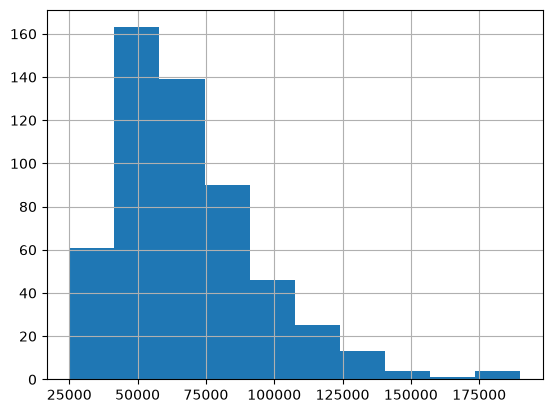

(np.float64(68121.59706959708), np.float64(62000.0))

In [ ]:
house['price'].hist()
plt.show()
house['price'].mean(), house['price'].median()

# ПІДГОТОВКА ДАНИХ

Числові ознаки: `lotsize` (площа ділянки), `bedrooms` (спальні), `bathrms` (ванні), `stories` (поверхи), `garagepl` (місця в гаражі).

Категоріальні ознаки (yes/no): `airco` (кондиціонер), `prefarea` (престижний район), `driveway` (під'їзна дорога), `fullbase` (підвал).

Категорії кодуємо через `pd.get_dummies(..., drop_first=True)` — отримуємо стовпці `airco_yes`, `prefarea_yes` тощо (0/1).

In [ ]:
house_enc = pd.get_dummies(house, columns=["airco", "prefarea", "driveway", "fullbase"],
                           drop_first=True, dtype=int)

house_enc.head()

,rownames,price,lotsize,bedrooms,bathrms,stories,recroom,gashw,garagepl,airco_yes,prefarea_yes,driveway_yes,fullbase_yes
0,1,42000,5850,3,1,2,no,no,1,0,0,1,1
1,2,38500,4000,2,1,1,no,no,0,0,0,1,0
2,3,49500,3060,3,1,1,no,no,0,0,0,1,0
3,4,60500,6650,3,1,2,yes,no,0,0,0,1,0
4,5,61000,6360,2,1,1,no,no,0,0,0,1,0


# ГРАДІЄНТНИЙ СПУСК (МНОЖИННА РЕГРЕСІЯ З КАТЕГОРІЯМИ)

In [ ]:
Y = house_enc["price"]

cols = ["lotsize", "bedrooms", "bathrms", "stories", "garagepl",
        "airco_yes", "prefarea_yes", "driveway_yes", "fullbase_yes"]
X = house_enc[cols]

mean = X.mean(axis=0)
std = X.std(axis=0)

Z = (X - mean) / std

n, k = Z.shape
w = np.zeros(k)
b = 0
lr = 0.1
losses = []

for step in range(300):
  pred = Z @ w + b
  error = pred - Y
  losses.append((error ** 2).mean())
  grad_w = 2 * Z.T @ error / n
  grad_b = 2 * error.mean()
  w = w - lr * grad_w
  b = b - lr * grad_b

  if step % 30 == 0:
    print(f"step={step} b={b:.2f}")
    count_metrics(Y, pred)

w_real = w / std
b_real = b - (w * mean / std).sum()

print()
print("Ваги (стандартизовані):")
print(w)
print("b =", b)
print()
print("Ваги (реальні одиниці):")
print(w_real)
print("b_real =", b_real)

step=0 b=13624.32
MAE: 68121.59706959708 | MSE: 5352278701.307693 | R2: -6.520131809109133 | 
step=30 b=68054.13
MAE: 11422.028899514537 | MSE: 242071345.7141363 | R2: 0.6598816077096359 | 
step=60 b=68121.51
MAE: 11410.735154386322 | MSE: 242040280.01249883 | R2: 0.6599252560665496 | 
step=90 b=68121.60
MAE: 11409.991206109338 | MSE: 242040183.94479847 | R2: 0.6599253910449037 | 
step=120 b=68121.60
MAE: 11409.942675731441 | MSE: 242040183.51311976 | R2: 0.6599253916514267 | 
step=150 b=68121.60
MAE: 11409.939437192874 | MSE: 242040183.51116434 | R2: 0.6599253916541742 | 
step=180 b=68121.60
MAE: 11409.939219630662 | MSE: 242040183.51115552 | R2: 0.6599253916541865 | 
step=210 b=68121.60
MAE: 11409.939204991042 | MSE: 242040183.51115546 | R2: 0.6599253916541866 | 
step=240 b=68121.60
MAE: 11409.939204005572 | MSE: 242040183.5111555 | R2: 0.6599253916541866 | 
step=270 b=68121.60
MAE: 11409.93920393923 | MSE: 242040183.51115546 | R2: 0.6599253916541866 | 

Ваги (стандартизовані):
lotsi

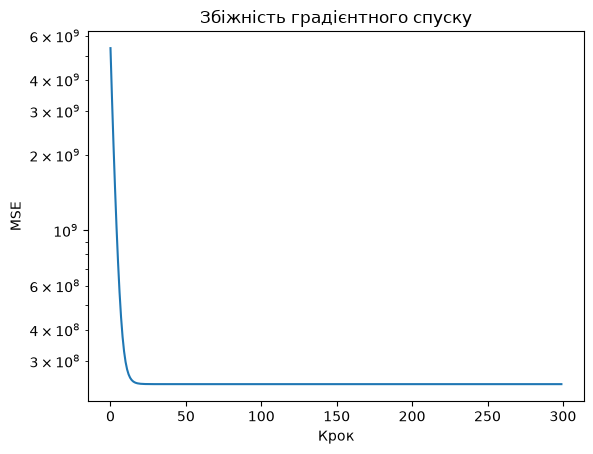

In [ ]:
plt.plot(losses)
plt.yscale("log")
plt.xlabel("Крок")
plt.ylabel("MSE")
plt.title("Збіжність градієнтного спуску")
plt.show()

# ЯКІСТЬ МОДЕЛІ

MAE: 11409.939203934762 | MSE: 242040183.51115546 | R2: 0.6599253916541866 | 


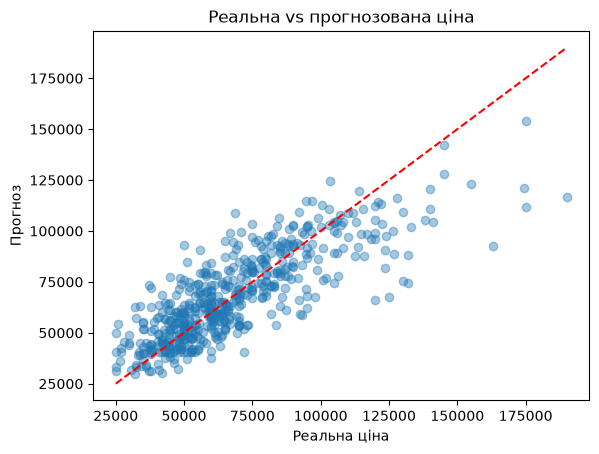

In [ ]:
pred_all = X @ w_real + b_real
count_metrics(Y, pred_all)

plt.scatter(Y, pred_all, alpha=0.4)
plt.plot([Y.min(), Y.max()], [Y.min(), Y.max()], "r--")
plt.xlabel("Реальна ціна")
plt.ylabel("Прогноз")
plt.title("Реальна vs прогнозована ціна")
plt.show()

# ПРОГНОЗ ВАРТОСТІ БУДИНКУ

In [ ]:
test = [6000, 3, 2, 2, 1, 1, 1, 1, 0]
price = test @ w_real + b_real

print(f"Прогнозована вартість будинку: {price:.0f}")

Прогнозована вартість будинку: 98280


In [ ]:
sample = house_enc.sample(5, random_state=1)
sample = sample.assign(predicted=(sample[cols] @ w_real + b_real).round())
sample[["price", "predicted"] + cols]

,price,predicted,lotsize,bedrooms,bathrms,stories,garagepl,airco_yes,prefarea_yes,driveway_yes,fullbase_yes
207,69500,50116.0,4350,2,1,1,0,0,0,1,1
90,47000,58153.0,6060,3,1,1,0,0,0,1,1
255,64500,59969.0,3450,3,1,2,1,0,0,1,1
453,73500,71803.0,7980,3,1,1,1,0,1,1,0
484,62900,65040.0,4880,3,1,1,2,0,1,1,0
